# Bab 7 — Results Presentation and Discussion

Notebook pendamping Bab 7 Level 7. Jalankan sel dari atas ke bawah, dan **jalankan skrip atau notebook Bab 2, 4, 5, dan 6 lebih dulu**. Bagian A sampai I mengikuti halaman bab (bootstrap membutuhkan sekitar satu menit). Bagian **Praktik** berisi kegiatan yang tidak ada di halaman: menulis kalimat hasilmu sendiri dan memeriksanya, menambah kalimat ke buku bukti, dan melihat apa yang berubah (dan tidak berubah) pada interval bila jumlah ulangan bootstrap ditambah.

Analisis bootstrap dan pangsa varians bersifat **eksploratori**. Gambar tampil langsung di notebook.

## Learning Objectives

Setelah mengerjakan notebook ini, kamu mampu:

- Menulis kalimat hasil dari fakta yang terlacak dan memeriksanya dengan pemeriksa angka dan kata berlebihan.
- Menambah kalimat ke buku bukti dengan jenis dan bukti yang benar.
- Melihat bahwa menambah ulangan bootstrap menstabilkan batas interval, bukan otomatis mempersempitnya.

## Langkah 0: Pindah ke folder utama proyek

In [1]:
import os
import sys
from pathlib import Path

if not Path("data").exists() and not Path("examples").exists():
    os.chdir("../..")

ROOT = Path.cwd()
# alat bantu bersama Level 7 (examples/level-7/_research.py)
sys.path.insert(0, str(Path("examples/level-7").resolve()))

## Bagian A: Siapkan alat dan baca hasil Bab 6

In [2]:
import json
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import AgglomerativeClustering, KMeans
from sklearn.metrics import adjusted_rand_score
from sklearn.mixture import GaussianMixture
from sklearn.preprocessing import StandardScaler

import _research as rs

RESULTS = rs.RESULTS_DIR
SEED = 42
protocol = json.loads((RESULTS / "05_protocol.json").read_text(encoding="utf-8"))
rq1 = json.loads((RESULTS / "06_rq1_summary.json").read_text(encoding="utf-8"))
rq2 = pd.read_csv(RESULTS / "06_rq2_scaling.csv", index_col="perlakuan")
rq3 = pd.read_csv(RESULTS / "06_rq3_algorithms.csv", index_col="algoritma")
grid = pd.read_csv(RESULTS / "06_dbscan_grid.csv")
ksens = pd.read_csv(RESULTS / "06_k_sensitivity.csv", index_col="k")
profile = pd.read_csv(RESULTS / "06_cluster_profile.csv", index_col=0)
crosstab = pd.read_csv(RESULTS / "06_crosstab_diagnosis.csv", index_col=0)
manifest = json.loads((RESULTS / "06_run_manifest.json").read_text(encoding="utf-8"))
clarifications = json.loads((RESULTS / "06_clarifications.json").read_text(encoding="utf-8"))
print("Eksekusi dari Bab 6:", manifest["eksekusi_dijalankan"], "| klarifikasi:", len(clarifications))


def fmt(value, digits=3):
    """Angka dengan koma desimal, seperti penulisan bahasa Indonesia."""
    return f"{value:.{digits}f}".replace(".", ",")

Eksekusi dari Bab 6: 156 | klarifikasi: 5


## Bagian B: Tabel hasil

In [3]:
def md_table(frame, digits=3):
    header = "| " + " | ".join(map(str, frame.columns)) + " |"
    divider = "|" + "|".join("---" for _ in frame.columns) + "|"
    rows = []
    for row in frame.itertuples(index=False):
        rows.append("| " + " | ".join(fmt(v, digits) if isinstance(v, (float, np.floating)) and not np.isnan(v) else ("-" if isinstance(v, float) else str(v)) for v in row) + " |")
    return "\n".join([header, divider, *rows])


table_rq3 = rq3.reset_index()[["algoritma", "kelompok", "silhouette", "davies_bouldin", "calinski_harabasz", "ari_vs_diagnosis", "nmi_vs_diagnosis"]]
table_rq3.columns = ["Algoritma", "Kelompok", "Silhouette (naik lebih baik)", "Davies-Bouldin (turun lebih baik)", "Calinski-Harabasz (naik lebih baik)", "ARI vs diagnosis", "NMI vs diagnosis"]
dbscan_row = pd.DataFrame([["DBSCAN", "tidak ada konfigurasi valid", np.nan, np.nan, np.nan, np.nan, np.nan]], columns=table_rq3.columns)
table_rq3 = pd.concat([table_rq3, dbscan_row], ignore_index=True)

table_rq2 = rq2.reset_index().rename(columns={"perlakuan": "Perlakuan skala", "ari_mean": "ARI rata-rata", "ari_min": "ARI minimum", "ari_max": "ARI maksimum"})
tables = {
    "Tabel 1. RQ3, perbandingan algoritma (K = 2, ruang baseline)": md_table(table_rq3),
    "Tabel 2. RQ2, ARI terhadap baseline menurut perlakuan skala": md_table(table_rq2),
}
for title, text in tables.items():
    print(title)
    print(text)

Tabel 1. RQ3, perbandingan algoritma (K = 2, ruang baseline)
| Algoritma | Kelompok | Silhouette (naik lebih baik) | Davies-Bouldin (turun lebih baik) | Calinski-Harabasz (naik lebih baik) | ARI vs diagnosis | NMI vs diagnosis |
|---|---|---|---|---|---|---|
| KMeans | 2 | 0,343 | 1,321 | 267,692 | 0,654 | 0,532 |
| Agglomerative | 2 | 0,339 | 1,370 | 248,629 | 0,575 | 0,457 |
| GMM | 2 | 0,314 | 1,377 | 247,284 | 0,774 | 0,661 |
| DBSCAN | tidak ada konfigurasi valid | - | - | - | - | - |
Tabel 2. RQ2, ARI terhadap baseline menurut perlakuan skala
| Perlakuan skala | ARI rata-rata | ARI minimum | ARI maksimum | proporsi_ari>=0.95 |
|---|---|---|---|---|
| StandardScaler (baseline) | 0,982 | 0,965 | 1,000 | 1,000 |
| tanpa skala | 0,496 | 0,496 | 0,496 | 0,000 |
| MinMaxScaler | 0,896 | 0,896 | 0,896 | 0,000 |


## Bagian C: Ciri yang berbeda antar kelompok

In [4]:
def split_name(name):
    if name.startswith("mean "):
        return "mean", name[5:]
    if name.startswith("worst "):
        return "worst", name[6:]
    return "error", name[:-6]


parts = pd.DataFrame([split_name(n) for n in profile.index], columns=["statistik", "ukuran"], index=profile.index)
profile_parts = profile.join(parts)
profile_parts["selisih_mutlak"] = profile_parts["selisih"].abs()
by_measure = profile_parts.groupby("ukuran")["selisih_mutlak"].mean().sort_values(ascending=False)
by_statistic = profile_parts.groupby("statistik")["selisih_mutlak"].mean().sort_values(ascending=False)
print("Rata-rata |selisih z-score| menurut ukuran inti sel:")
print(by_measure.round(2).to_string())
print("Menurut jenis statistik:")
print(by_statistic.round(2).to_string())

Rata-rata |selisih z-score| menurut ukuran inti sel:
ukuran
concave points       1.53
perimeter            1.43
concavity            1.42
radius               1.40
compactness          1.36
area                 1.35
fractal dimension    0.71
symmetry             0.67
smoothness           0.64
texture              0.50
Menurut jenis statistik:
statistik
worst    1.28
mean     1.22
error    0.80


## Bagian D: Analisis eksploratori (bootstrap dan pangsa varians)

In [5]:
# EKSPLORATORI 1: bootstrap data (200 ulangan) untuk melihat ketidakpastian ARI terhadap diagnosis.
X_df, y = rs.load_wdbc()
X_raw = X_df.to_numpy(dtype=float)
n = len(X_raw)
rng = np.random.default_rng(SEED)
boot = {"KMeans": [], "Agglomerative": [], "GMM": []}
for _ in range(200):
    idx = rng.choice(n, size=n, replace=True)
    Xs = StandardScaler().fit_transform(X_raw[idx])
    truth = y.to_numpy()[idx]
    boot["KMeans"].append(adjusted_rand_score(truth, KMeans(n_clusters=2, n_init=10, random_state=SEED).fit_predict(Xs)))
    boot["Agglomerative"].append(adjusted_rand_score(truth, AgglomerativeClustering(n_clusters=2, linkage="ward").fit_predict(Xs)))
    boot["GMM"].append(adjusted_rand_score(truth, GaussianMixture(n_components=2, covariance_type="full", n_init=5, random_state=SEED).fit_predict(Xs)))
boot = pd.DataFrame(boot)
ci = pd.DataFrame({"rata_rata": boot.mean(), "bawah_2.5": boot.quantile(0.025), "atas_97.5": boot.quantile(0.975)})
diffs = pd.DataFrame({"GMM - KMeans": boot["GMM"] - boot["KMeans"], "KMeans - Agglomerative": boot["KMeans"] - boot["Agglomerative"], "GMM - Agglomerative": boot["GMM"] - boot["Agglomerative"]})
diff_ci = pd.DataFrame({"rata_rata": diffs.mean(), "bawah_2.5": diffs.quantile(0.025), "atas_97.5": diffs.quantile(0.975), "proporsi_positif": (diffs > 0).mean()})
print("EKSPLORATORI, bootstrap 200 ulangan, ARI vs diagnosis:")
print(ci.round(3).to_string())
print("Selisih ARI berpasangan:")
print(diff_ci.round(3).to_string())

# EKSPLORATORI 2: pangsa varians fitur pada data TANPA skala.
variance = X_df.var()
share = (variance / variance.sum()).sort_values(ascending=False)
print("Pangsa varians terbesar (data tanpa skala):")
print((100 * share.head(3)).round(2).to_string())
print("Dua fitur teratas bersama:", round(float(100 * share.head(2).sum()), 2), "persen dari total varians")

EKSPLORATORI, bootstrap 200 ulangan, ARI vs diagnosis:
               rata_rata  bawah_2.5  atas_97.5
KMeans             0.674      0.602      0.780
Agglomerative      0.617      0.393      0.792
GMM                0.742      0.626      0.843
Selisih ARI berpasangan:
                        rata_rata  bawah_2.5  atas_97.5  proporsi_positif
GMM - KMeans                0.068     -0.012      0.157             0.940
KMeans - Agglomerative      0.057     -0.112      0.278             0.695
GMM - Agglomerative         0.126     -0.032      0.343             0.905
Pangsa varians terbesar (data tanpa skala):
worst area    71.73
mean area     27.41
area error     0.46
Dua fitur teratas bersama: 99.14 persen dari total varians


## Bagian E: Daftar angka yang boleh dikutip

In [6]:
# Semua angka yang boleh dikutip di teks. Teks dibuat dari daftar ini, bukan diketik tangan.
km, ag, gm = rq3.loc["KMeans"], rq3.loc["Agglomerative"], rq3.loc["GMM"]
facts = {
    "seed_mean": rq1["stab_seed_mean"], "seed_min": rq1["stab_seed_min"],
    "sub_mean": rq1["stab_sub_mean"], "sub_min": rq1["stab_sub_min"], "sub_max": rq1["stab_sub_max"],
    "std_base": rq2.loc["StandardScaler (baseline)", "ari_mean"], "std_none": rq2.loc["tanpa skala", "ari_mean"], "std_minmax": rq2.loc["MinMaxScaler", "ari_mean"],
    "threshold": protocol["aturan_keputusan"]["ambang_praktis_sama_ARI"],
    "km_sil": km["silhouette"], "ag_sil": ag["silhouette"], "gm_sil": gm["silhouette"],
    "km_db": km["davies_bouldin"], "ag_db": ag["davies_bouldin"], "gm_db": gm["davies_bouldin"],
    "km_ari": km["ari_vs_diagnosis"], "ag_ari": ag["ari_vs_diagnosis"], "gm_ari": gm["ari_vs_diagnosis"],
    "km_nmi": km["nmi_vs_diagnosis"], "ag_nmi": ag["nmi_vs_diagnosis"], "gm_nmi": gm["nmi_vs_diagnosis"],
    "noise_min": grid["noise_persen"].min(), "noise_max": grid["noise_persen"].max(),
    "malignant_c0": crosstab.loc[0, "malignant"] / crosstab.loc[0].sum(), "malignant_c1": crosstab.loc[1, "malignant"] / crosstab.loc[1].sum(),
    "top2_share": 100 * float(share.head(2).sum()),
    "gm_minus_km_low": diff_ci.loc["GMM - KMeans", "bawah_2.5"], "gm_minus_km_high": diff_ci.loc["GMM - KMeans", "atas_97.5"],
    "km_minus_ag_low": diff_ci.loc["KMeans - Agglomerative", "bawah_2.5"], "km_minus_ag_high": diff_ci.loc["KMeans - Agglomerative", "atas_97.5"],
    "c1_top_measure_diff": by_measure.iloc[0], "c1_bottom_measure_diff": by_measure.iloc[-1],
}
counts = {"c0": int(crosstab.loc[0].sum()), "c1": int(crosstab.loc[1].sum()), "off": int(crosstab.loc[0, "malignant"] + crosstab.loc[1, "benign"]), "n": int(crosstab.values.sum())}
facts["off_percent"] = 100 * counts["off"] / counts["n"]
pool = set()
for value in facts.values():
    for digits in (1, 2, 3):
        pool.add(fmt(float(value), digits))
print("Jumlah fakta yang boleh dikutip:", len(facts), "| bentuk angka yang sah:", len(pool))

Jumlah fakta yang boleh dikutip: 33 | bentuk angka yang sah: 80


## Bagian F: Buku bukti: hasil, interpretasi, pembahasan, keterbatasan

In [7]:
F = lambda key, d=3: fmt(float(facts[key]), d)
ledger = []
def add(kind, text, evidence):
    ledger.append({"id": f"{kind[0].upper()}{sum(1 for e in ledger if e['jenis'] == kind) + 1}", "jenis": kind, "kalimat": text, "bukti": evidence})

# HASIL: hanya angka dan pengamatan
add("hasil", f"Pada 20 seed, ARI rata-rata antar-pasangan K-Means (K = 2) adalah {F('seed_mean')} (minimum {F('seed_min')}; 190 pasangan).", "06_rq1_summary.json")
add("hasil", f"Pada 50 subsampel (80 persen), ARI rata-rata terhadap pengelompokan data penuh adalah {F('sub_mean')} dengan rentang {F('sub_min')} sampai {F('sub_max')}.", "06_rq1_summary.json")
add("hasil", f"ARI terhadap baseline: StandardScaler {F('std_base')}, tanpa skala {F('std_none')}, MinMaxScaler {F('std_minmax')}. Ambang praktis sama adalah {F('threshold', 2)}.", "06_rq2_scaling.csv")
add("hasil", f"Silhouette: K-Means {F('km_sil')}, Agglomerative {F('ag_sil')}, GMM {F('gm_sil')}. ARI terhadap diagnosis: K-Means {F('km_ari')}, Agglomerative {F('ag_ari')}, GMM {F('gm_ari')}.", "06_rq3_algorithms.csv")
add("hasil", f"Delapan konfigurasi DBSCAN semuanya menghasilkan satu kelompok, dengan noise {F('noise_min', 1)} sampai {F('noise_max', 1)} persen; tidak ada yang valid menurut protokol.", "06_dbscan_grid.csv")
add("hasil", f"Pada K-Means baseline, proporsi malignant adalah {F('malignant_c0')} pada kelompok 0 ({counts['c0']} titik) dan {F('malignant_c1')} pada kelompok 1 ({counts['c1']} titik).", "06_crosstab_diagnosis.csv")
add("hasil", f"(Eksploratori) Selisih ARI terhadap diagnosis, GMM dikurangi K-Means, memiliki interval bootstrap 95 persen {F('gm_minus_km_low')} sampai {F('gm_minus_km_high')}; K-Means dikurangi Agglomerative {F('km_minus_ag_low')} sampai {F('km_minus_ag_high')}.", "bootstrap 200 ulangan, bagian explore")
add("hasil", f"(Eksploratori) Pada data tanpa skala, dua fitur dengan varians terbesar menyumbang {F('top2_share', 1)} persen dari total varians.", "bagian explore")

# INTERPRETASI: alasan dari hasil, dengan bahasa hati-hati
add("interpretasi", "Pengelompokan K-Means dua kelompok pada data terstandarisasi tampak konsisten terhadap seed dan pengambilan sampel pada dataset ini.", "H1, H2")
add("interpretasi", "Konsisten tidak sama dengan bermakna: hasil ini tidak menunjukkan bahwa kelompok mencerminkan kategori nyata.", "H1, H2")
add("interpretasi", f"Cara menyamakan skala mengubah pengelompokan pada data ini: tanpa skala ({F('std_none')}) jauh berbeda dari baseline, dan MinMaxScaler ({F('std_minmax')}) pun tidak memenuhi ambang praktis sama ({F('threshold', 2)}).", "H3")
add("interpretasi", f"Dugaan: pada data tanpa skala, jarak didominasi beberapa fitur berskala besar. Dua fitur teratas menyumbang {F('top2_share', 1)} persen dari total varians, sejalan dengan dugaan ini, tetapi dugaan belum diuji langsung.", "H8")
add("interpretasi", f"Peringkat algoritma berbeda antar jenis metrik: K-Means unggul pada metrik internal, GMM unggul pada ARI dan NMI terhadap diagnosis pada eksekusi utama. Namun pada analisis eksploratori, interval selisih ARI GMM dikurangi K-Means mencakup nol ({F('gm_minus_km_low')} sampai {F('gm_minus_km_high')}), sehingga keunggulan GMM tidak jelas melampaui ketidakpastian sampel.", "H4, H7")
add("interpretasi", "Tidak ada algoritma yang dapat dinyatakan unggul secara umum tanpa menyebut tujuan evaluasinya.", "H4")
add("interpretasi", "Kelompok 1 pada K-Means ditandai nilai tinggi pada fitur kontur dan ukuran (concavity, concave points, perimeter), dan memuat proporsi malignant yang tinggi; ini deskripsi keselarasan, bukan penjelasan sebab.", "H6")
add("interpretasi", "Dugaan: kepadatan titik pada 30 dimensi terstandarisasi relatif seragam sehingga DBSCAN tidak menemukan kelompok terpisah. Dugaan ini belum diuji.", "H5")

# PEMBAHASAN terhadap pustaka (dasar: abstrak atau ringkasan, lihat Bab 3)
add("pembahasan", "Gagasan bahwa pengelompokan yang baik seharusnya stabil terhadap gangguan data (Ben-Hur dkk., 2002) sejalan dengan cara RQ1 diukur; hasil RQ1 konsisten dengan gagasan itu, tetapi tidak membuktikan adanya struktur kelompok.", "L3; abstrak atau ringkasan")
add("pembahasan", "Perbedaan peringkat antara metrik internal dan eksternal sejalan dengan pandangan bahwa evaluasi clustering bergantung pada konteks dan tujuan (von Luxburg dkk., 2012; Hennig, 2015).", "L1, L2; abstrak atau ringkasan")
add("pembahasan", "ARI dan NMI yang dikoreksi untuk kebetulan (Vinh dkk., 2010) dipakai pada validasi eksternal; dengan 569 titik dan dua kelompok, koreksi ini tidak menjadi masalah utama.", "L4; abstrak atau ringkasan")
add("pembahasan", "Angka penelitian ini tidak dibandingkan dengan angka makalah lain karena tidak ada makalah pada matriks Bab 3 yang memakai data, protokol, dan metrik yang sama.", "Bab 3")

# KETERBATASAN
add("keterbatasan", "Hasil berlaku untuk satu dataset (569 sampel) dan konfigurasi yang ditetapkan protokol.", "protokol")
add("keterbatasan", "K = 2 dipengaruhi jumlah kelas diagnosis, sehingga ARI terhadap diagnosis tidak independen dari pilihan itu.", "protokol, pengungkapan")
add("keterbatasan", "Protokol ditulis setelah demonstrasi Bab 1 pada data yang sama, sehingga tidak sepenuhnya buta terhadap data.", "protokol, pengungkapan")
add("keterbatasan", "Hanya DBSCAN yang disetel, sehingga upaya penyetelan antar algoritma tidak setara.", "protokol")
add("keterbatasan", "Tinjauan pustaka bersifat terarah dan kelima sumber hanya dibaca abstrak atau ringkasannya.", "Bab 3")
add("keterbatasan", "Persetujuan etik dan status de-identifikasi data tidak diketahui; tidak ada klaim klinis.", "Bab 4")
add("keterbatasan", "Analisis bootstrap dan pangsa varians bersifat eksploratori dan tidak ada di protokol.", "Bab 5")

ledger_df = pd.DataFrame(ledger)
print(ledger_df["jenis"].value_counts().to_string())

jenis
hasil           8
interpretasi    8
keterbatasan    7
pembahasan      4


## Bagian G: Memeriksa angka dan kata berlebihan

In [8]:
OVERCLAIM = ["membuktikan", "terbukti", "pasti", "menyebabkan", "tidak diragukan", "selalu", "mengonfirmasi", "terbaik"]


def untraceable_numbers(text):
    """Angka desimal berkoma di teks yang tidak ada di daftar fakta."""
    found = re.findall(r"-?\d+,\d+", text)
    return [x for x in found if x not in pool and x not in {"0,95", "0,9"}]


def overclaim_words(text):
    """Kata berlebihan, kecuali bila 'tidak' atau 'bukan' muncul tepat sebelumnya. Negasi jauh dari katanya bisa terlewat."""
    low = text.lower()
    found = []
    for word in OVERCLAIM:
        for match in re.finditer(r"\b" + word + r"\b", low):   # kata utuh: "pasti" tidak cocok di dalam "ketidakpastian"
            window = low[max(0, match.start() - 12):match.start()]
            if "tidak " not in window and "bukan " not in window:
                found.append(word)
                break
    return found


problems = []
for row in ledger:
    bad_numbers = untraceable_numbers(row["kalimat"])
    bad_words = overclaim_words(row["kalimat"])
    if bad_numbers or bad_words:
        problems.append((row["id"], bad_numbers, bad_words))
print("Kalimat bermasalah pada buku bukti:", problems if problems else "tidak ada")

demo = [
    "ARI GMM terhadap diagnosis sebesar 0,812, membuktikan bahwa GMM adalah algoritma terbaik.",
    "Ukuran inti sel menyebabkan kelompok ganas, tidak diragukan lagi.",
]
for sentence in demo:
    print("Demo:", sentence)
    print("   angka tak terlacak:", untraceable_numbers(sentence), "| kata berlebihan:", overclaim_words(sentence))

Kalimat bermasalah pada buku bukti: tidak ada
Demo: ARI GMM terhadap diagnosis sebesar 0,812, membuktikan bahwa GMM adalah algoritma terbaik.
   angka tak terlacak: ['0,812'] | kata berlebihan: ['membuktikan', 'terbaik']
Demo: Ukuran inti sel menyebabkan kelompok ganas, tidak diragukan lagi.
   angka tak terlacak: [] | kata berlebihan: ['menyebabkan', 'tidak diragukan']


## Bagian H: Gambar hasil dengan ketidakpastian

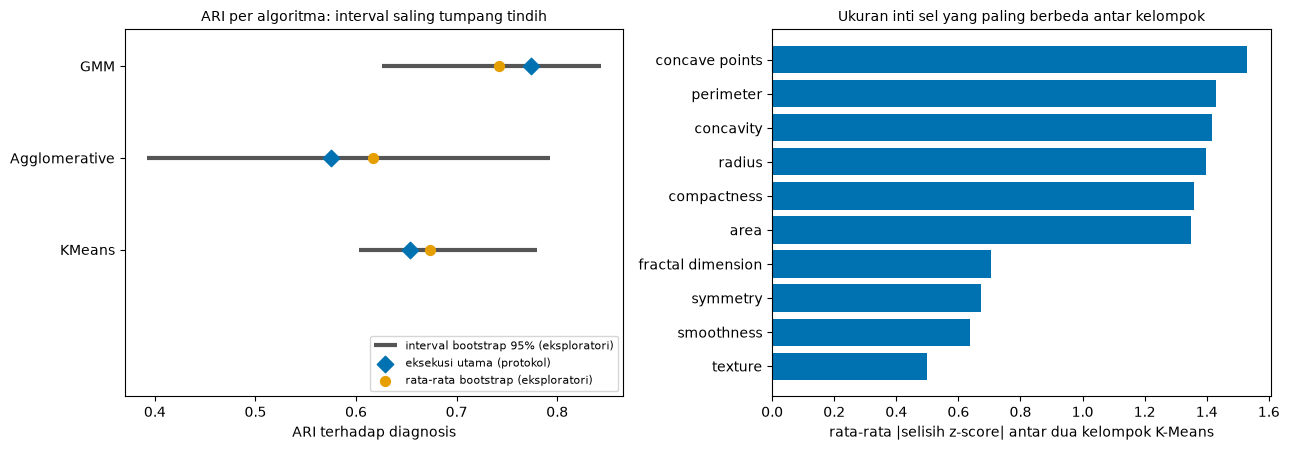

In [9]:
names = ["KMeans", "Agglomerative", "GMM"]
pos = np.arange(len(names))
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
axes[0].hlines(pos, [ci.loc[m, "bawah_2.5"] for m in names], [ci.loc[m, "atas_97.5"] for m in names], color="#555555", linewidth=3, label="interval bootstrap 95% (eksploratori)")
axes[0].scatter([rq3.loc[m, "ari_vs_diagnosis"] for m in names], pos, marker="D", s=70, color="#0072B2", zorder=3, label="eksekusi utama (protokol)")
axes[0].scatter([ci.loc[m, "rata_rata"] for m in names], pos, marker="o", s=50, color="#E69F00", zorder=3, label="rata-rata bootstrap (eksploratori)")
axes[0].set_yticks(pos)
axes[0].set_yticklabels(names)
axes[0].set_ylim(-1.6, 2.4)   # ruang kosong di bawah untuk legenda
axes[0].set_xlabel("ARI terhadap diagnosis")
axes[0].set_title("ARI per algoritma: interval saling tumpang tindih", fontsize=10)
axes[0].legend(fontsize=8, loc="lower right")
ordered = by_measure.sort_values()
axes[1].barh(ordered.index, ordered.values, color="#0072B2")
axes[1].set_xlabel("rata-rata |selisih z-score| antar dua kelompok K-Means")
axes[1].set_title("Ukuran inti sel yang paling berbeda antar kelompok", fontsize=10)
plt.tight_layout()
plt.show()

## Bagian I: Menyusun bagian Hasil dan Pembahasan

In [10]:
titles = {"hasil": "Hasil", "interpretasi": "Interpretasi", "pembahasan": "Pembahasan terhadap penelitian terdahulu", "keterbatasan": "Keterbatasan"}
lines = []
for kind, title in titles.items():
    lines.append(f"**{title}**")
    lines.append("")
    for row in ledger:
        if row["jenis"] == kind:
            lines.append(f"- ({row['id']}) {row['kalimat']}")
    lines.append("")
report = "\n".join(lines)
RESULTS.mkdir(exist_ok=True)
(RESULTS / "07_results_discussion.md").write_text(report, encoding="utf-8")
(RESULTS / "07_tables.md").write_text("\n\n".join(f"**{t}**\n\n{x}" for t, x in tables.items()) + "\n", encoding="utf-8")
ledger_df.to_csv(RESULTS / "07_claim_ledger.csv", index=False, encoding="utf-8")
ci.to_csv(RESULTS / "07_bootstrap_ari.csv", encoding="utf-8")
diff_ci.to_csv(RESULTS / "07_bootstrap_differences.csv", encoding="utf-8")
by_measure.to_csv(RESULTS / "07_profile_by_measure.csv", encoding="utf-8")
(RESULTS / "07_facts.json").write_text(json.dumps({k: float(v) for k, v in facts.items()}, indent=2), encoding="utf-8")
print("Kalimat per jenis:", ledger_df["jenis"].value_counts().to_dict())
print("Berkas hasil disimpan di examples/level-7/results/ (awalan 07_)")

Kalimat per jenis: {'hasil': 8, 'interpretasi': 8, 'keterbatasan': 7, 'pembahasan': 4}
Berkas hasil disimpan di examples/level-7/results/ (awalan 07_)


## Praktik 1: Tulis kalimat hasilmu dan periksa

Kalimat di bawah sengaja berlebihan. Perbaiki sampai pemeriksa tidak menandainya, **tanpa** mengetik angka dari ingatan: gunakan `F('nama_fakta')`. Daftar nama fakta tersedia di `facts`.

In [11]:
print("Nama fakta:", list(facts)[:12], "...")

my_sentence = f"ARI GMM terhadap diagnosis adalah {F('gm_ari')}, membuktikan GMM terbaik."
print(my_sentence)
print("Angka tak terlacak:", untraceable_numbers(my_sentence))
print("Kata berlebihan   :", overclaim_words(my_sentence))

Nama fakta: ['seed_mean', 'seed_min', 'sub_mean', 'sub_min', 'sub_max', 'std_base', 'std_none', 'std_minmax', 'threshold', 'km_sil', 'ag_sil', 'gm_sil'] ...
ARI GMM terhadap diagnosis adalah 0,774, membuktikan GMM terbaik.
Angka tak terlacak: []
Kata berlebihan   : ['membuktikan', 'terbaik']


## Praktik 2: Tambah kalimat ke buku bukti

Tambahkan satu kalimat interpretasi atau keterbatasan milikmu. Selama masih berisi `ISI`, kalimat tidak ditambahkan. Tulis bukti yang bisa ditunjuk (berkas, bagian kode, atau nomor kalimat), dan pastikan kalimatnya lolos pemeriksa.

In [12]:
new_kind = "keterbatasan"
new_text = "ISI"
new_evidence = "ISI"

if "ISI" in (new_text, new_evidence):
    print("Kalimat belum diisi; buku bukti tidak berubah.")
else:
    problems_new = (untraceable_numbers(new_text), overclaim_words(new_text))
    print("Pemeriksa:", problems_new)
    if not any(problems_new):
        add(new_kind, new_text, new_evidence)
print(pd.DataFrame(ledger)["jenis"].value_counts().to_dict())

Kalimat belum diisi; buku bukti tidak berubah.
{'hasil': 8, 'interpretasi': 8, 'keterbatasan': 7, 'pembahasan': 4}


## Praktik 3: Jumlah ulangan dan interval

Bootstrap memakai generator yang sama, jadi 50 ulangan pertama adalah bagian dari 200 ulangan. Bandingkan interval selisih ARI GMM dikurangi K-Means menurut jumlah ulangan. Tidak ada perhitungan ulang, hanya mengambil subset dari `diffs`.

In [13]:
for b in (50, 100, 200):
    d = diffs["GMM - KMeans"].iloc[:b]
    low, high = d.quantile(0.025), d.quantile(0.975)
    print(f"B = {b:3d}: interval {low:+.3f} sampai {high:+.3f}  (lebar {high - low:.3f}), proporsi positif {float((d > 0).mean()):.3f}")

B =  50: interval -0.008 sampai +0.146  (lebar 0.153), proporsi positif 0.960
B = 100: interval -0.018 sampai +0.145  (lebar 0.163), proporsi positif 0.940
B = 200: interval -0.012 sampai +0.157  (lebar 0.168), proporsi positif 0.940


## Latihan

1. Perbaiki `my_sentence` sampai kedua pemeriksa kosong. Apakah kalimat itu sekarang memuat satu klaim yang masih bisa dipertanyakan? Jelaskan.
2. Tulis satu kalimat dugaan tentang DBSCAN yang ditandai "belum diuji", lalu tambahkan sebagai interpretasi. Bukti apa yang akan menguji dugaan itu?
3. Pada Praktik 3, apakah interval selisih mencakup nol pada setiap B, dan apakah lebarnya mengecil saat B naik? Untuk apa ulangan tambahan berguna?
4. Tulis satu kalimat yang lolos pemeriksa kata tetapi tetap berlebihan. Mengapa pemeriksa melewatkannya?

## Ringkasan

- Kalimat hasil dibuat dari fakta yang terlacak; angka tidak diketik dari ingatan.
- Pemeriksa angka dan kata hanyalah jaring pengaman, dan perlu diuji seperti kode lain.
- Menambah ulangan bootstrap menstabilkan estimasi batas interval, tetapi tidak otomatis mempersempitnya; interval yang mencakup nol berarti perbedaan tidak jelas pada data ini.
- Analisis eksploratori selalu diberi label dan tidak dicampur dengan hasil yang direncanakan.